# NII dinámico, ganancias en riesgo y EVaR con escenarios de Hull-White y Nelson-Siegel dinámico

**Pregunta:** si las tasas del banco no se someten a un solo choque sino que se simulan, ¿cuánto margen neto de intereses gana su balance en los próximos 12 meses, cuánto lo cambia un movimiento de 200 puntos base, y cuán grandes son las ganancias en riesgo y el valor económico en riesgo de una distribución de Hull-White cuando se lee junto a ellos el error de Monte Carlo?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los notebooks 01 a 03 de este tema
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

Al terminar este notebook puedes:

- ajustar una curva de Nelson-Siegel y una de Svensson a las tasas cero de una fecha, leer sus parámetros y errores, y decir qué son los factores del Nelson-Siegel dinámico;
- proyectar el margen neto de intereses (NII) mensual de un balance en 12 meses con balance constante, con partidas que reprecian en momentos distintos y con un beta de depósitos;
- generar escenarios de tasa corta de Hull-White de un factor y convertirlos en distribuciones de NII y de EVE, y leer las ganancias en riesgo (EaR) y el valor económico en riesgo (EVaR) con el error de Monte Carlo del cuantil;
- explicar por qué una EaR medida contra una base plana puede salir negativa.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.irrbb import curves, eve_nii, shocks, simulation, slotting
from riskvalidation.validation import irrbb as rv_irrbb

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Datos

Los datos son el caso C14, el riesgo de tasa de interés en el libro de banca (IRRBB) del banco que quebró en marzo de 2023, tal como Contraste lo versiona: los reportes de condición de la FDIC (FDIC BankFind financials, https://api.fdic.gov/banks/financials) y la curva a la par del Tesoro de EE. UU. (https://home.treasury.gov/resource-center/data-chart-center/interest-rates), fuentes de dominio público de la clase de licencia `mirror-allowed`. El banco es **real en agregado y sintético en comportamiento**, así que los plazos de reprecio, el beta de depósitos y la reversión a la media de Hull-White los declara o los ajusta Contraste y quedan rotulados en el documento. El dinero está en miles de USD, las tasas son decimales con capitalización continua, y una EaR, EVaR o delta NII positivo es una pérdida.

- **Archivos que se leen:** `data/derived/C14/vd-2022-q2.json` (`outputs.curve`, `dynamic_nii`, `ear_evar`, `balance_sheet`; `impact`), `vd-2021-q4.json` (`outputs.out_of_sample`, `curve`; `tests`) y `vd-2022-q4.json` (`outputs.curve`).
- **No están en el repositorio:** el historial trimestral del costo de los depósitos y de la curva del Tesoro, que el proceso del producto lee de la raíz de datos. Donde el método necesita un historial de factores (Paso 2), el notebook construye uno **construido y con semilla** y lo dice.

La celda siguiente carga los tres documentos.

In [2]:
# Cargar las tres fechas de valoración (el notebook está tres carpetas bajo la raíz) y los 19 puntos medios
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C14"
quarters = ("2021-Q4", "2022-Q2", "2022-Q4")
docs = {q: json.loads((derived / f"vd-{q.lower()}.json").read_text(encoding="utf-8")) for q in quarters}
out = docs["2022-Q2"]["outputs"]
MID = slotting.bucket_grid().midpoints
LANG = "es"  # los campos bilingües de los documentos se leen en este idioma
NAME = {"base": "base", "parallel-up": "paralelo al alza", "parallel-down": "paralelo a la baja"}
NAME.update({"asset": "activo", "liability": "pasivo", True: "sí", False: "no"})
print("fechas de valoración:", [d["outputs"]["valuation_date"] for d in docs.values()])

fechas de valoración: ['2021-12-31', '2022-06-30', '2022-12-31']


## Método

El método tiene cinco pasos: (1) ajustar curvas paramétricas, (2) los factores del Nelson-Siegel dinámico y su pronóstico, (3) el NII mensual del balance, (4) los escenarios de Hull-White y las distribuciones de NII y de EVE, (5) la verificación fuera de muestra de la proyección.

### Paso 1: Nelson-Siegel y Svensson

Una curva paramétrica describe toda la curva de rendimientos con pocos números. La curva de Nelson-Siegel da el rendimiento al plazo $m$ con cuatro parámetros, un nivel, una pendiente, una curvatura y un decaimiento $\tau$ (Nelson y Siegel, 1987, https://doi.org/10.1086/296409; dossier 05, D.5):

$$y(m) = \beta_0 + \beta_1\, \frac{1 - e^{-m/\tau}}{m/\tau} + \beta_2 \left( \frac{1 - e^{-m/\tau}}{m/\tau} - e^{-m/\tau} \right)$$

Svensson agrega una segunda joroba, $\beta_3 \left( \frac{1 - e^{-m/\tau_2}}{m/\tau_2} - e^{-m/\tau_2} \right)$ (Svensson, 1994, https://doi.org/10.3386/w4871). Para un $\tau$ fijo la curva es lineal en los betas, así que `fit_nelson_siegel` del motor resuelve mínimos cuadrados para cada $\tau$ de una grilla (0,25 a 10 años en pasos de 0,25) y se queda con el mejor; `fit_svensson` hace una búsqueda en grilla sobre los dos decaimientos seguida de un pulido acotado, y contiene a Nelson-Siegel, así que su error nunca es mayor. La celda siguiente ajusta ambas a las 12 tasas cero del 2022-06-30 e imprime los parámetros y la raíz del error cuadrático medio en puntos base.

Nelson-Siegel: β0 0.03131 β1 -0.02332 β2 0.00855 τ 0.25
    error (pb) 12.59
Svensson: β0 0.01526 β1 -0.00569 β2 0.04614 β3 0.05473
    τ1 0.608 τ2 11.472 | error (pb) 10.09
primer valor de la grilla de tau: 0.25
0.25 y: tasas cero 0.01716 | Nelson-Siegel 0.01883 | Svensson 0.01842
20 y: tasas cero 0.03445 | Nelson-Siegel 0.03113 | Svensson 0.03282


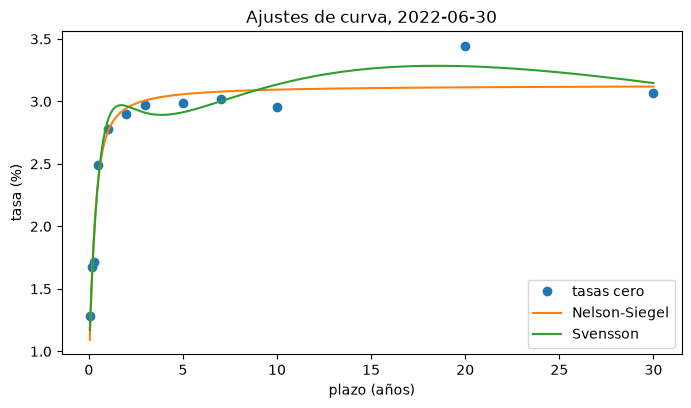

In [3]:
# Ajustar Nelson-Siegel y Svensson a las 12 tasas cero del 2022-06-30 y dibujar las dos curvas
points = out["curve"]["points"]
tenors = np.array([p["tenor_years"] for p in points])
zero = np.array([p["zero_rate"] for p in points])
ns = curves.fit_nelson_siegel(tenors, zero)
sv = curves.fit_svensson(tenors, zero)
print(f"Nelson-Siegel: β0 {ns.beta0:.5f} β1 {ns.beta1:.5f} β2 {ns.beta2:.5f} τ {ns.tau:.2f}")
print(f"    error (pb) {ns.rmse * 1e4:.2f}")
print(f"Svensson: β0 {sv.beta0:.5f} β1 {sv.beta1:.5f} β2 {sv.beta2:.5f} β3 {sv.beta3:.5f}")
print(f"    τ1 {sv.tau1:.3f} τ2 {sv.tau2:.3f} | error (pb) {sv.rmse * 1e4:.2f}")
print("primer valor de la grilla de tau:", curves.DEFAULT_TAU_GRID[0])
ns_at = curves.nelson_siegel_yield(tenors, ns.beta0, ns.beta1, ns.beta2, ns.tau)
sv_at = curves.svensson_yield(tenors, sv.beta0, sv.beta1, sv.beta2, sv.beta3, sv.tau1, sv.tau2)
for k in (2, 10):
    print(f"{tenors[k]:g} y: tasas cero {zero[k]:.5f} | Nelson-Siegel {ns_at[k]:.5f} | Svensson {sv_at[k]:.5f}")
grid = np.linspace(0.05, 30, 300)
ns_grid = curves.nelson_siegel_yield(grid, ns.beta0, ns.beta1, ns.beta2, ns.tau)
sv_grid = curves.svensson_yield(grid, sv.beta0, sv.beta1, sv.beta2, sv.beta3, sv.tau1, sv.tau2)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(tenors, zero * 100, "o", label="tasas cero")
ax.plot(grid, ns_grid * 100, label="Nelson-Siegel")
ax.plot(grid, sv_grid * 100, label="Svensson")
ax.set_xlabel("plazo (años)")
ax.set_ylabel("tasa (%)")
ax.set_title("Ajustes de curva, 2022-06-30")
ax.legend()
plt.show()

Svensson sigue más de cerca los 12 puntos que Nelson-Siegel, 10,09 pb frente a 12,59 pb de raíz del error cuadrático medio, porque su segunda joroba puede doblarse hacia el punto de 20 años; el precio son dos parámetros más. Ambas curvas siguen errando ese punto (la tasa cero de 3,445 por ciento frente a 3,113 y 3,282 por ciento) y el punto de 3 meses (1,716 por ciento frente a 1,883 y 1,842 por ciento). El decaimiento de Nelson-Siegel es 0,25 años, el primer valor de su grilla, así que el mejor ajuste quiere un decaimiento más rápido que el que la grilla permite y el resultado depende de la grilla. Una curva ajustada es un modelo de la curva de mercado, no la curva de mercado, y la figura muestra un solo día.

### Paso 2: Nelson-Siegel dinámico

Diebold y Li (2006, https://doi.org/10.1016/j.jeconom.2005.03.005) fijan el decaimiento y dejan que los tres betas se muevan en el tiempo como un factor de **nivel**, uno de **pendiente** y uno de **curvatura**, cada uno siguiendo un AR(1), lo que da un modelo de pronóstico de curvas completas. Con el decaimiento $\lambda = 0{,}0609$ por mes y plazos $m$ en meses, las cargas de los tres factores son

$$y_t(m) = L_t + S_t\, \frac{1 - e^{-\lambda m}}{\lambda m} + C_t \left( \frac{1 - e^{-\lambda m}}{\lambda m} - e^{-\lambda m} \right), \qquad f_{t+1} = c + \phi\, f_t + \varepsilon_t$$

El artículo dice que el decaimiento se eligió para maximizar la carga de curvatura exactamente a los 30 meses; el motor documenta que el máximo está en 29,446 meses y que el artículo redondea. La celda siguiente lo verifica en una grilla fina con las cargas del propio motor, y luego ajusta los tres factores en cada una de las tres fechas versionadas por mínimos cuadrados sobre los plazos que comparten (`fit_dns_factors`). El nivel debería subir a lo largo del ciclo de alzas de 2022.

λ = 0.0609 | la carga de curvatura tiene su máximo en (meses): 29.446
2021-Q4: nivel   0.02068 | pendiente  -0.02086 | curvatura  -0.00942
2022-Q2: nivel   0.03095 | pendiente  -0.01271 | curvatura   0.01523
2022-Q4: nivel   0.03837 | pendiente   0.00875 | curvatura   0.00005


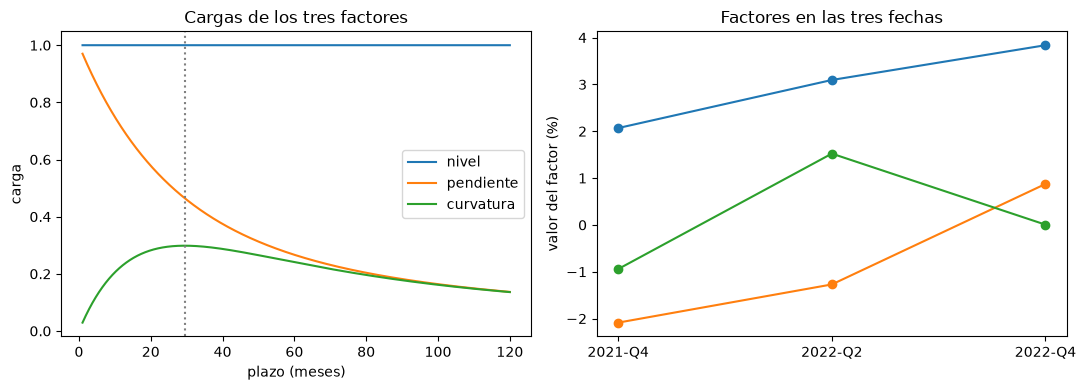

In [4]:
# Hallar el máximo de la carga de curvatura en una grilla fina y ajustar los tres factores en las tres fechas
fine = np.arange(1.0, 120.0, 0.001)
loadings = curves.dns_loadings(fine)
peak = float(fine[np.argmax(loadings[:, 2])])
print("λ =", curves.DIEBOLD_LI_LAMBDA, "| la carga de curvatura tiene su máximo en (meses):", round(peak, 3))
shared_years = np.array([0.25, 0.5, 1.0, 2.0, 3.0, 5.0, 7.0, 10.0, 20.0, 30.0])
months = np.round(shared_years * 12)
panel = []
for d in docs.values():
    by_tenor = {round(p["tenor_years"], 2): p["zero_rate"] for p in d["outputs"]["curve"]["points"]}
    panel.append([by_tenor[round(float(y), 2)] for y in shared_years])
factors = curves.fit_dns_factors(months, np.array(panel))
for q, f in zip(docs, factors):
    print(f"{q}: nivel {f[0]:9.5f} | pendiente {f[1]:9.5f} | curvatura {f[2]:9.5f}")
names = ("nivel", "pendiente", "curvatura")
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
for j, label in enumerate(names):
    left.plot(fine, loadings[:, j], label=label)
    right.plot(list(docs), factors[:, j] * 100, marker="o", label=label)
left.axvline(peak, color="grey", linestyle=":")
left.set_xlabel("plazo (meses)")
left.set_ylabel("carga")
left.set_title("Cargas de los tres factores")
left.legend()
right.set_ylabel("valor del factor (%)")
right.set_title("Factores en las tres fechas")
fig.tight_layout()
plt.show()

El panel izquierdo muestra las tres cargas: la de nivel es plana en uno, la de pendiente decae de uno a cero, y la de curvatura sube hasta una joroba cuyo máximo marca la línea punteada en 29,446 meses, no en los 30 exactos a los que redondea el artículo. El panel derecho muestra los factores que movió el ciclo de alzas: el nivel sube de 2,07 a 3,10 y a 3,84 por ciento, y la pendiente va de -2,09 a -1,27 y a +0,88 por ciento, que es el paso de una curva con pendiente positiva a una invertida. Tres fechas son muy pocas para decir algo de la dinámica, y por eso el pronóstico del paso siguiente parte de un historial construido.

Para pronosticar, el modelo necesita un historial de factores, al menos cuatro fechas. Los documentos versionados traen solo tres fechas y el historial completo del proceso del producto no está en el repositorio, así que la celda siguiente construye un **historial construido y con semilla** de 48 meses de factores AR(1) alrededor de los valores de 2022-Q2, que no son datos del banco. Llama a `forecast_dns_factors` (un AR(1) ajustado a cada factor por mínimos cuadrados, innovaciones gaussianas independientes de la varianza residual ajustada, trayectorias que parten de la última fila del historial y no usan nada posterior) y a `dns_scenarios` (las mismas trayectorias a través de las cargas hacia rendimientos en plazos elegidos), e imprime la dispersión del nivel a 12 meses y del rendimiento a 10 años.

trayectorias de factores (trayectorias, meses, factores): (2000, 12, 3)
nivel en el mes 12 (media, percentiles 5 y 95):
    [0.03122 0.02821 0.03415]
rendimiento a 10 años en el mes 12 (media, percentiles 5 y 95):
    [0.03124 0.02804 0.03442]


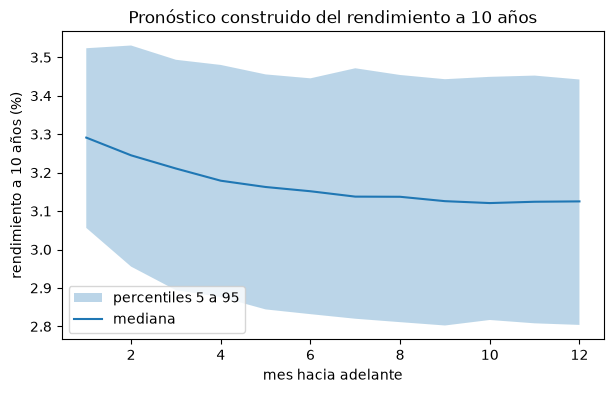

In [5]:
# Un historial de factores construido y con semilla, el pronóstico de los factores y los rendimientos a 12 meses
rng = np.random.default_rng(42)
center = factors[1]
history = np.zeros((48, 3))
history[0] = center
for t in range(1, 48):
    history[t] = center + 0.9 * (history[t - 1] - center) + rng.normal(0, [0.0015, 0.002, 0.003])
paths = curves.forecast_dns_factors(history, 12, 2000, 42)
yields = simulation.dns_scenarios(history, np.array([12.0, 60.0, 120.0]), 12, 2000, 42)
print("trayectorias de factores (trayectorias, meses, factores):", paths.shape)
level12, y10 = paths[:, -1, 0], yields[:, -1, 2]
print("nivel en el mes 12 (media, percentiles 5 y 95):")
print("   ", np.round([level12.mean(), *np.percentile(level12, [5, 95])], 5))
print("rendimiento a 10 años en el mes 12 (media, percentiles 5 y 95):")
print("   ", np.round([y10.mean(), *np.percentile(y10, [5, 95])], 5))
ahead = np.arange(1, 13)
low, mid, high = (np.percentile(yields[:, :, 2], p, axis=0) * 100 for p in (5, 50, 95))
fig, ax = plt.subplots(figsize=(7, 4))
ax.fill_between(ahead, low, high, alpha=0.3, label="percentiles 5 a 95")
ax.plot(ahead, mid, label="mediana")
ax.set_xlabel("mes hacia adelante")
ax.set_ylabel("rendimiento a 10 años (%)")
ax.set_title("Pronóstico construido del rendimiento a 10 años")
ax.legend()
plt.show()

La banda es la dispersión de 2.000 trayectorias del rendimiento a 10 años en los próximos 12 meses: se abre aproximadamente con la raíz del tiempo y termina entre 2,80 y 3,44 por ciento en torno a una media de 3,12 por ciento. Los factores son series AR(1) con innovaciones independientes, así que la banda es simétrica y tiene el ancho que le da el ruido construido, nada más. Lo que la imagen muestra es cómo la función convierte un historial de factores en escenarios de curvas completas; lo que no muestra es un pronóstico de las tasas del banco, porque el historial del que parte es inventado y está centrado en los factores de 2022-Q2.

### Paso 3: el NII mensual del balance

El NII dinámico proyecta el margen neto de intereses mes a mes durante 12 meses. Cada partida con interés tiene un saldo, un lado (activo o pasivo), una tasa actual y una regla de reprecio: después de su mes de reprecio $k$ la partida gana $\text{spread} + \beta\, r$, donde $r$ es la tasa corta en el mes de su último reprecio y $\beta$ es el traspaso (1 para un activo indexado al mercado, el beta de depósitos para un depósito). Una partida con $k = 0$ reprecia todos los meses; una con $k \ge 1$ conserva su tasa actual en los meses anteriores a $k$ y luego reprecia en $k, 2k, \dots$. El NII mensual es

$$NII_m = \frac{1}{12} \sum_i \text{lado}_i\ B_i\, (1 + g)^{m/12}\ \text{tasa}_{i,m}$$

con $g$ el crecimiento anual del balance; $g = 0$ es el **balance constante** del estándar (los flujos que vencen y reprecian se reemplazan por otros idénticos, BCBS d368 DIS70.5; dossier 05, D.6). El reporte no da los plazos de reprecio, así que el proceso del producto los declara: 2 meses para la banda de tres meses o menos, 8 meses para tres a doce meses, más allá del horizonte para el resto (sintéticos, en el documento). La celda siguiente lista las diez partidas de la proyección de 2022-Q2.

In [6]:
# Listar las diez partidas del NII dinámico con su saldo, tasa, spread, beta y mes de reprecio
dyn = out["dynamic_nii"]
items = dyn["items"]
print(dyn["balance_sheet_assumption"]["description"][LANG])
print("lado | saldo | tasa | spread | beta | reprecio (meses)")
for it in items:
    cols = [it["item_id"], NAME[it["side"]], f"{it['balance']:,.0f}", f"{it['rate0']:.4f}"]
    cols += [f"{it['spread']:.4f}", f"{it['beta']:.3f}", str(it["reprice_months"])]
    print(*cols, sep=" | ")

Balance constante: los flujos que vencen o reprecian se reemplazan por otros idénticos. Las partidas no sensibles a tasas (otros activos, otros pasivos) se omiten; los depósitos sin interés quedan a tasa cero.
lado | saldo | tasa | spread | beta | reprecio (meses)
D1 | activo | 14,808,000 | 0.0041 | -0.0087 | 1.000 | 0
D2 | activo | 55,065,000 | 0.0310 | 0.0182 | 1.000 | 2
D3 | activo | 3,777,000 | 0.0310 | 0.0182 | 1.000 | 8
D4 | activo | 12,019,000 | 0.0310 | 0.0310 | 0.000 | 120
D5 | activo | 50,000 | 0.0187 | 0.0059 | 1.000 | 2
D6 | activo | 556,000 | 0.0187 | 0.0059 | 1.000 | 8
D7 | activo | 121,338,000 | 0.0187 | 0.0187 | 0.000 | 120
D8 | pasivo | 116,177,000 | 0.0000 | 0.0000 | 0.000 | 0
D9 | pasivo | 73,976,000 | 0.0027 | 0.0017 | 0.075 | 0
D10 | pasivo | 3,703,000 | 0.0128 | 0.0000 | 1.000 | 0


La función `simulate_nii` del motor recibe los arreglos de las partidas y una trayectoria de tasa corta de 12 a 36 meses. Los escenarios versionados usan una trayectoria plana: la tasa corta de la fecha (la tasa cero de la segunda banda) más el choque, con piso en cero (200 pb al alza, 200 pb a la baja), mantenida los 12 meses. La celda siguiente reconstruye las tres trayectorias con `apply_floor`, corre `simulate_nii` en cada una y muestra el total de cada una; en la misma celda corre la trayectoria base con un crecimiento del balance de 5 por ciento, que escala cada mes por $(1 + g)^{m/12}$, y dibuja el NII mensual de los cuatro casos. El delta contra la base tiene la pérdida positiva: un número negativo es una ganancia.

base             tasa corta 0.01279
    NII 12 meses    4,297,741 | delta contra la base            0
paralelo al alza tasa corta 0.03279
    NII 12 meses    5,356,610 | delta contra la base   -1,058,869
paralelo a la baja tasa corta 0.00000
    NII 12 meses    3,620,426 | delta contra la base      677,315
NII 12 meses con crecimiento de 5%: 4395363


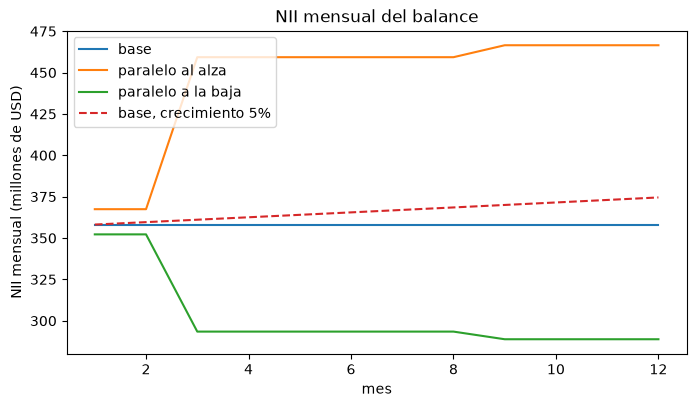

In [7]:
# Correr simulate_nii del motor en tres trayectorias planas de tasa corta y en la base con crecimiento de 5%
cols = {k: np.array([it[k] for it in items]) for k in ("balance", "rate0", "spread", "beta", "reprice_months")}
side = np.array([1 if it["side"] == "asset" else -1 for it in items])
args = (cols["balance"], side, cols["rate0"], cols["spread"], cols["beta"], cols["reprice_months"])
r0 = np.array(out["curve"]["zero_rates_at_midpoints"])
r_short = float(r0[1])
floor = out["scenarios"][0]["floor"]
result = {}
for key, bp in (("base", 0.0), ("parallel-up", 200.0), ("parallel-down", -200.0)):
    start = float(shocks.apply_floor(np.array([r_short]), np.array([bp]), floor)[0])
    result[key] = simulation.simulate_nii(*args, np.full(12, start), 0.0)
    delta = result["base"].total - result[key].total
    print(f"{NAME[key]:16s} tasa corta {start:.5f}")
    print(f"    NII 12 meses {result[key].total:12,.0f} | delta contra la base {delta:12,.0f}")
grown = simulation.simulate_nii(*args, np.full(12, r_short), 0.05)
print("NII 12 meses con crecimiento de 5%:", round(grown.total))
fig, ax = plt.subplots(figsize=(8, 4.2))
for key in result:
    ax.plot(np.arange(1, 13), result[key].monthly_nii / 1e3, label=NAME[key])
ax.plot(np.arange(1, 13), grown.monthly_nii / 1e3, linestyle="--", label="base, crecimiento 5%")
ax.set_xlabel("mes")
ax.set_ylabel("NII mensual (millones de USD)")
ax.set_title("NII mensual del balance")
ax.legend()
plt.show()

El NII base es plano en 358 millones al mes porque la tasa corta se mantiene en 1,28 por ciento. La línea de +200 pb sube en el mes 3, cuando las partidas que reprecian a los 2 meses toman la nueva tasa, y otra vez en el mes 9 para las que reprecian a los 8; la de -200 pb baja en los mismos meses, solo 128 pb porque el piso en cero detiene la tasa corta en 0 por ciento. En los 12 meses el choque al alza es una ganancia de 1.058.869 y el choque a la baja una pérdida de 677.315, y la línea punteada muestra el crecimiento de 5 por ciento levantando cada mes en cerca de 0,4 por ciento mensual sobre la base. La imagen muestra una trayectoria plana por caso, no una distribución: eso viene ahora.

### Paso 4: escenarios de Hull-White, EaR y EVaR

Una distribución de NII y de EVE necesita una distribución de trayectorias de tasas. El modelo de Hull-White de un factor tiene la tasa corta $r(t) = x(t) + \alpha(t)$ con $dx = -a\, x\, dt + \sigma\, dW$, $x(0) = 0$, y una parte determinística elegida para ajustar la curva de hoy (Hull y White, 1990, https://doi.org/10.1093/rfs/3.4.573; la forma del motor es la de los textos, Brigo y Mercurio, 2006, ec. 3.34):

$$\alpha(t) = f(0, t) + \frac{\sigma^2}{2 a^2}\, \left(1 - e^{-a t}\right)^2$$

con $f(0,t)$ la tasa a plazo instantánea de la curva inicial. La función `hw1f_scenarios` del motor simula la grilla mensual de forma exacta y usa trayectorias antitéticas (la segunda mitad refleja la primera). El proceso del producto fija la reversión a la media $a$ en 0,10 al año (declarada, sintética) y ajusta $\sigma$ a los cambios diarios del rendimiento del Tesoro a 3 meses de los últimos tres años. Para cada trayectoria calcula el NII de los 12 meses con `simulate_nii` y el EVE de los flujos conductuales bajo el desplazamiento paralelo que implica la trayectoria (el cambio de la tasa corta en el año, con piso): esa composición es el diseño del proceso del producto, no una función del motor. Luego `ear_evar` toma la diferencia, con pérdida positiva, entre la base y el cuantil $(1 - \text{nivel})$:

$$EaR = NII_{base} - Q_{1-\text{nivel}}(NII), \qquad EVaR = EVE_{base} - Q_{1-\text{nivel}}(EVE)$$

La corrida del producto tiene 100.000 trayectorias y semilla 42. Toma unos segundos, así que la celda siguiente la corre e imprime los niveles de 95 y 99 por ciento con su error de Monte Carlo.

In [8]:
# Correr Hull-White: 100.000 trayectorias antitéticas, NII y EVE por trayectoria, EaR y EVaR con su error
dist = out["ear_evar"]
a_hw, sigma_hw = (p["value"] for p in dist["parameters"])
flows = np.zeros(19)
for it in out["balance_sheet"]["items"]:
    for row in it["cash_flows"]["behavioural"]:
        flows[row["bucket"] - 1] += row["amount"]
rates = simulation.hw1f_scenarios(zero, tenors, a_hw, sigma_hw, dist["horizon_months"], dist["n_paths"], dist["seed"])
nii_paths = np.array([simulation.simulate_nii(*args, q[:12], 0.0).total for q in rates])
shifts = (rates[:, -1] - rates[:, 0]) * 1e4
eve_paths = np.array([eve_nii.eve(flows, shocks.apply_floor(r0, np.full(19, s), floor), MID) for s in shifts])
base_nii, base_eve = result["base"].total, eve_nii.eve(flows, r0, MID)
print("a =", a_hw, "| σ =", round(sigma_hw, 6), "| trayectorias y semilla:", rates.shape[0], dist["seed"])
print("NII base y EVE base:", round(base_nii), round(base_eve))
main = {}
for lvl in (0.95, 0.99):
    got = simulation.ear_evar(nii_paths, eve_paths, base_nii, base_eve, lvl)
    err = simulation.ear_evar_mc_error(nii_paths, eve_paths, lvl, dist["n_batches"], antithetic=True)
    main[lvl] = (got, err)
    print(f"nivel {lvl:.2f}: EaR {got.ear:12,.0f} (±{err.ear_se:,.0f})")
    print(f"    EVaR {got.evar:12,.0f} (±{err.evar_se:,.0f})")

a = 0.1 | σ = 0.00504 | trayectorias y semilla: 100000 42
NII base y EVE base: 4297741 7036780
nivel 0.95: EaR     -585,961 (±995)
    EVaR    3,948,056 (±4,285)
nivel 0.99: EaR     -482,023 (±1,451)
    EVaR    4,370,301 (±6,623)


La EaR en ambos niveles es **negativa**: el NII en el cuantil de 1 por ciento está sobre el NII base. La proyección base mantiene la tasa corta plana en el 1,28 por ciento de hoy, mientras las trayectorias de Hull-White siguen la curva a plazo, que a mediados de 2022 tenía pendiente positiva, así que la distribución del NII está centrada muy por encima de la base. Una EaR medida contra una base plana dice entonces que las ganancias serían mayores en el 99 por ciento de las trayectorias, no que no haya riesgo; el lado adverso debe leerse contra el centro de la propia distribución. La celda siguiente imprime la media y los cuantiles de las trayectorias y del NII, y dibuja las dos distribuciones.

tasa corta hoy y en el mes 12 (media, percentiles 5 y 95): 0.01279
    [0.02903 0.02117 0.03689]
NII de los 12 meses: base, media de las trayectorias, percentiles 1, 5 y 95:
    4297741 5138757 [4779764. 4883702. 5393813.]
proporción de trayectorias con NII sobre la base: 1.0


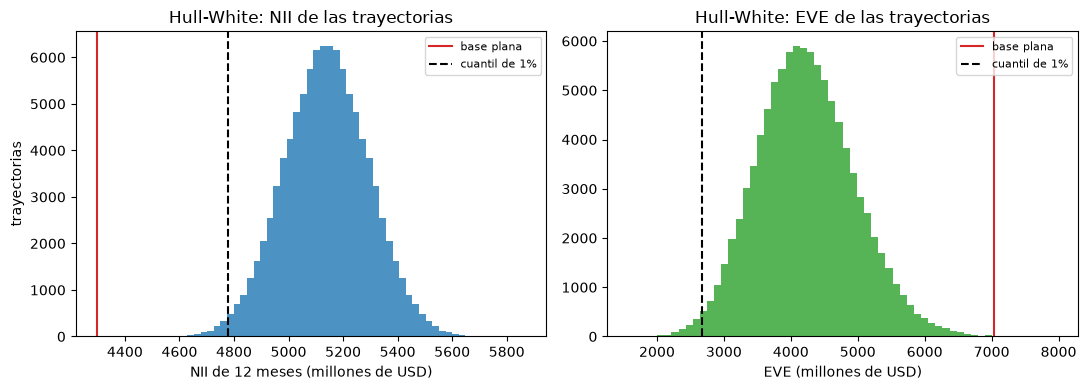

In [9]:
# Dónde queda la distribución frente a la base plana: las tasas, el NII y el EVE de las trayectorias
r12 = rates[:, -1]
today = round(float(rates[:, 0].mean()), 5)
print("tasa corta hoy y en el mes 12 (media, percentiles 5 y 95):", today)
print("   ", np.round([r12.mean(), *np.percentile(r12, [5, 95])], 5))
q_nii = np.percentile(nii_paths, [1, 5, 95])
print("NII de los 12 meses: base, media de las trayectorias, percentiles 1, 5 y 95:")
print("   ", round(base_nii), round(float(nii_paths.mean())), np.round(q_nii))
print("proporción de trayectorias con NII sobre la base:", round(float((nii_paths > base_nii).mean()), 4))
q_eve = np.percentile(eve_paths, 1)
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
left.hist(nii_paths / 1e3, bins=60, color="tab:blue", alpha=0.8)
left.axvline(base_nii / 1e3, color="tab:red", label="base plana")
left.axvline(q_nii[0] / 1e3, color="black", linestyle="--", label="cuantil de 1%")
left.set_xlabel("NII de 12 meses (millones de USD)")
left.set_ylabel("trayectorias")
left.set_title("Hull-White: NII de las trayectorias")
left.legend(fontsize=8)
right.hist(eve_paths / 1e3, bins=60, color="tab:green", alpha=0.8)
right.axvline(base_eve / 1e3, color="tab:red", label="base plana")
right.axvline(q_eve / 1e3, color="black", linestyle="--", label="cuantil de 1%")
right.set_xlabel("EVE (millones de USD)")
right.set_title("Hull-White: EVE de las trayectorias")
right.legend(fontsize=8)
fig.tight_layout()
plt.show()

El histograma izquierdo queda enteramente a la derecha de la línea roja: cada una de las 100.000 trayectorias gana más que la base plana, porque la tasa corta de las trayectorias tiene una media de 2,90 por ciento en el mes 12 frente a 1,28 por ciento hoy. El cuantil de 1 por ciento, la línea punteada, queda entonces sobre la base y la EaR es negativa; la lectura honesta es que las ganancias no están en riesgo contra una base que se queda quieta, y que la base es el lado débil de la medida. El histograma derecho es el EVE, y aquí la línea punteada queda bien bajo la base roja: el EVaR de 4.370.301 al 99 por ciento es el 62 por ciento del EVE base de 7.036.780. La imagen no muestra la cola de otro modelo, solo la de este.

La segunda lectura: el error de Monte Carlo. La celda siguiente repite la corrida con 2.000 y 10.000 trayectorias e imprime cada estimación al 99 por ciento con su error, junto a las 100.000 de la corrida principal, y dibuja el error contra el número de trayectorias.

trayectorias       EaR 99    error      EVaR 99    error
       2,000     -480,611    7,071    4,305,713   30,669
      10,000     -480,337    5,715    4,356,301   22,474
     100,000     -482,023    1,451    4,370,301    6,623


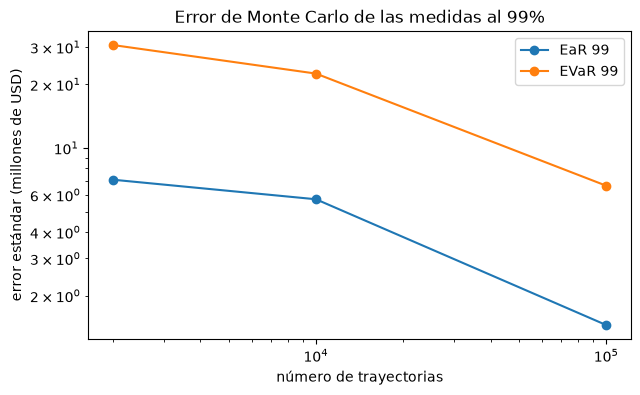

In [10]:
# El error de Monte Carlo de la EaR y el EVaR al 99 por ciento con 2.000, 10.000 y 100.000 trayectorias antitéticas
g99, e99 = main[0.99]
rows_mc = [(dist["n_paths"], g99.ear, e99.ear_se, g99.evar, e99.evar_se)]
for n in (2000, 10000):
    sample = simulation.hw1f_scenarios(zero, tenors, a_hw, sigma_hw, 12, n, dist["seed"])
    nii_n = np.array([simulation.simulate_nii(*args, q[:12], 0.0).total for q in sample])
    shifts_n = (sample[:, -1] - sample[:, 0]) * 1e4
    eve_n = np.array([eve_nii.eve(flows, shocks.apply_floor(r0, np.full(19, s), floor), MID) for s in shifts_n])
    got = simulation.ear_evar(nii_n, eve_n, base_nii, base_eve, 0.99)
    err = simulation.ear_evar_mc_error(nii_n, eve_n, 0.99, dist["n_batches"], antithetic=True)
    rows_mc.append((n, got.ear, err.ear_se, got.evar, err.evar_se))
rows_mc.sort()
print(f"{'trayectorias':>12s} {'EaR 99':>12s} {'error':>8s} {'EVaR 99':>12s} {'error':>8s}")
for n, ear, ear_se, evar, evar_se in rows_mc:
    print(f"{n:12,d} {ear:12,.0f} {ear_se:8,.0f} {evar:12,.0f} {evar_se:8,.0f}")
fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog([r[0] for r in rows_mc], [r[2] / 1e3 for r in rows_mc], marker="o", label="EaR 99")
ax.loglog([r[0] for r in rows_mc], [r[4] / 1e3 for r in rows_mc], marker="o", label="EVaR 99")
ax.set_xlabel("número de trayectorias")
ax.set_ylabel("error estándar (millones de USD)")
ax.set_title("Error de Monte Carlo de las medidas al 99%")
ax.legend()
plt.show()

Los dos errores bajan al crecer el número de trayectorias, de unos 30 millones de dólares de error de EVaR con 2.000 trayectorias a menos de 7 millones con 100.000, y la pendiente en los ejes logarítmicos es más suave que el menos un medio de los sorteos independientes, porque el error se estima a su vez con 20 lotes y los pares antitéticos cambian la constante. Las estimaciones mismas quedan a pocos errores unas de otras, así que 2.000 trayectorias ya ubican el EVaR al 99 por ciento a cerca de 2 por ciento de la cifra de 100.000 trayectorias. La imagen muestra el error de un cuantil, que es mayor que el de una media con el mismo tamaño de muestra; el motor lo devuelve junto a la estimación para que el validador lea ambos.

### Paso 5: la verificación fuera de muestra

Una proyección se gana la confianza al compararse con lo que ocurrió. La proyección hecha al 2021-12-31 para un choque de +200 pb (el cambio del NII a 12 meses, con la pérdida positiva) se puede comparar con el cambio de NII que el banco realizó en 2022 según los reportes. La prueba `irrbb.nii_out_of_sample` del motor recibe el cambio proyectado y el realizado y devuelve el error relativo con una luz (verde hasta 10 por ciento, ámbar hasta 25 por ciento, roja por encima: umbrales internos de Contraste). Las fechas de valoración del 2022-06-30 y del 2022-12-31 no tienen un año realizado posterior, porque el banco quebró el 2023-03-10 y no presentó reportes posteriores: el documento lo dice y la prueba devuelve `not_evaluated` en vez de un número. La celda siguiente corre la prueba con el par de 2021-Q4, dibuja el cambio proyectado y el realizado, y luego imprime la razón que dan las otras dos fechas.

2021-Q4: delta NII proyectado (pérdida positiva) -1,138,367
realizado -1,358,000
error relativo 0.1617 | diferencia en dinero 219,633
2022-Q2 no evaluado: Ningún año completo posterior a esta fecha está en los reportes: el banco quebró el 2023-03-10 y no presentó reportes posteriores, por lo que la proyección a 12 meses no se compara con una realizada.
2022-Q4 no evaluado: Ningún año completo posterior a esta fecha está en los reportes: el banco quebró el 2023-03-10 y no presentó reportes posteriores, por lo que la proyección a 12 meses no se compara con una realizada.


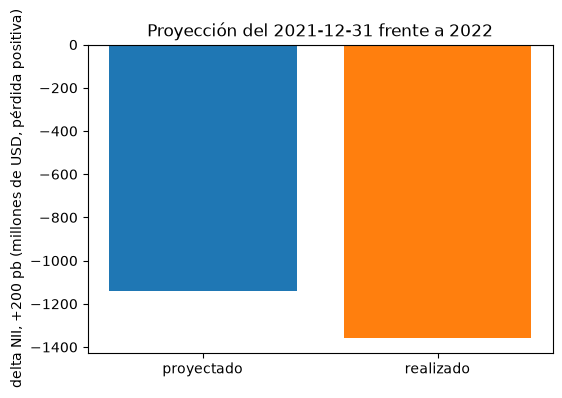

In [11]:
# Correr la prueba fuera de muestra con la proyección de 2021-Q4 y mostrar por qué las otras dos fechas no se evalúan
oos = docs["2021-Q4"]["outputs"]["out_of_sample"]
test_oos = rv_irrbb.nii_out_of_sample(oos["projected_delta_nii"], oos["realised_delta_nii"])
projected, realised = oos["projected_delta_nii"], oos["realised_delta_nii"]
print(f"2021-Q4: delta NII proyectado (pérdida positiva) {projected:,.0f}")
print(f"realizado {realised:,.0f}")
print(f"error relativo {test_oos.statistic:.4f} | diferencia en dinero {test_oos.metric:,.0f}")
for q in ("2022-Q2", "2022-Q4"):
    print(q, "no evaluado:", docs[q]["outputs"]["out_of_sample"]["reason"][LANG])
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["proyectado", "realizado"], [projected / 1e3, realised / 1e3], color=["tab:blue", "tab:orange"])
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_ylabel("delta NII, +200 pb (millones de USD, pérdida positiva)")
ax.set_title("Proyección del 2021-12-31 frente a 2022")
plt.show()

Las dos barras son negativas, lo que en esta convención de pérdida positiva significa que ambas son ganancias: la proyección para +200 pb decía que el banco ganaría 1,14 mil millones de dólares más, y el cambio realizado de 2022 fue una ganancia de 1,36 mil millones, un error relativo de 16,2 por ciento. Compara un choque con una trayectoria, así que verifica el orden de magnitud y el signo de la sensibilidad, no el pronóstico. Las otras dos fechas no tienen un año realizado porque el banco quebró el 2023-03-10 y no presentó reportes posteriores; la prueba lo dice con su razón y no devuelve ningún número, que es lo que lista la impresión de arriba. La imagen es una sola comparación, no una serie de contraste retrospectivo.

## Resultados

**Respuesta:** en los próximos 12 meses el balance gana un NII base de 4.297.741 (miles de USD) con la tasa corta fija en 1,28 por ciento; un movimiento de +200 pb lo sube en 1.058.869 y uno de -200 pb, detenido por el piso en cero, lo baja en 677.315. Con 100.000 trayectorias de Hull-White la EaR es -482.023 al 99 por ciento, negativa porque toda trayectoria gana más que la base plana, y el EVaR es 4.370.301 al 99 por ciento, con un error de Monte Carlo de 6.623.

- **Los ajustes de curva.** Nelson-Siegel ajusta las 12 tasas cero del 2022-06-30 con un error de 12,59 pb y Svensson con 10,09 pb, así que la segunda joroba compra 2,5 pb. Ambas fallan en el punto de 20 años y en el extremo corto. El decaimiento de Nelson-Siegel es 0,25 años, el valor más bajo de su grilla, así que un validador debe ensanchar la grilla antes de confiar en los betas.
- **Nelson-Siegel dinámico.** La carga de curvatura tiene su máximo en 29,446 meses con el decaimiento de 0,0609, no en los 30 exactos a los que redondea el artículo. El nivel sube de 2,07 a 3,10 y a 3,84 por ciento en las tres fechas, y la pendiente de -2,09 a -1,27 y a +0,88 por ciento. El pronóstico viene de un historial construido, así que su dispersión (el nivel a 12 meses entre 2,82 y 3,42 por ciento) muestra cómo funciona la función y no dice nada del banco.
- **El NII mensual.** Las partidas que reprecian todos los meses se mueven de una vez, las de 2 meses desde el mes 3 y las de 8 meses desde el mes 9. Los signos son opuestos a los de la brecha de reprecio del notebook 01, que dio una pérdida de 199.057 para +100 pb: la brecha trata la parte de los depósitos que ubica a la vista como reprecio al choque completo, mientras la proyección da a los depósitos con interés un beta de 0,075 y a los que no pagan interés ninguno. El efecto en ganancias de un alza de tasas es tanto una afirmación sobre el beta de depósitos como sobre el balance. Un crecimiento de 5 por ciento da 4.395.363 en los 12 meses.
- **EaR y EVaR.** La EaR es -585.961 al 95 por ciento y -482.023 al 99 por ciento, y el EVaR es 3.948.056 y 4.370.301. La tasa corta tiene una media de 2,90 por ciento en el mes 12 frente a 1,28 por ciento hoy, porque Hull-White sigue la curva a plazo, y el NII medio de las trayectorias es 5.138.757, 20 por ciento sobre la base. El EVaR de 4.370.301 es el 62 por ciento del EVE base de 7.036.780.
- **El error de Monte Carlo.** El EVaR al 99 por ciento es 4.305.713 con 2.000 trayectorias (error 30.669), 4.356.301 con 10.000 (22.474) y 4.370.301 con 100.000 (6.623). El error baja con el número de trayectorias, aunque no de forma suave, y las estimaciones quedan a pocos errores de la corrida principal.
- **La verificación fuera de muestra.** Al 2021-12-31 la proyección para +200 pb fue un cambio de -1.138.367 (una ganancia) frente a un cambio realizado de -1.358.000 en 2022: un error relativo de 0,1617. Al 2022-06-30 y al 2022-12-31 no hay año realizado, y la prueba es `not_evaluated` con la razón escrita, nunca un número.
- **Lo que el notebook no muestra.** El ajuste del traspaso al historial del banco y la estabilidad de los pesos replicantes (notebook 05), la comparación en tres fechas con las aproximaciones de brecha y de duración (notebook 07), y cualquier pronóstico de las tasas reales del banco: el historial de factores es construido.

## Resumen

- Una curva paramétrica comprime una curva de rendimientos en cuatro o seis números; Svensson contiene a Nelson-Siegel y nunca ajusta peor, y el decaimiento de Nelson-Siegel puede quedar en el borde de su grilla.
- El Nelson-Siegel dinámico hace de los tres factores series AR(1) y convierte un historial de factores en escenarios de curvas completas; aquí el historial es construido, porque el historial trimestral del banco no está en el repositorio.
- El NII mensual del balance depende de cuándo reprecia cada partida y del beta de depósitos; el balance constante es el supuesto del estándar.
- EaR y EVaR son diferencias de cuantiles de trayectorias simuladas, con un error de Monte Carlo que baja con el número de trayectorias; una EaR contra una base plana puede ser negativa cuando los escenarios siguen una curva a plazo ascendente.
- Una proyección se compara con el año realizado cuando lo hay; el banco no presentó reportes posteriores, así que dos de las tres fechas no lo tienen, y el motor lo dice en vez de devolver un número.

**Qué probar a continuación.** Cambia la reversión a la media `a_hw` y mira cómo la dispersión de la tasa a 12 meses mueve el EVaR más que la EaR. Después sigue con el notebook 05, las pruebas de validación.

## Referencias

- Nelson, C. R. y Siegel, A. F. (1987), Parsimonious modeling of yield curves, Journal of Business 60(4). https://doi.org/10.1086/296409
- Svensson, L. E. O. (1994), Estimating and interpreting forward interest rates: Sweden 1992-1994, NBER Working Paper 4871. https://doi.org/10.3386/w4871
- Diebold, F. X. y Li, C. (2006), Forecasting the term structure of government bond yields, Journal of Econometrics 130(2). https://doi.org/10.1016/j.jeconom.2005.03.005
- Hull, J. y White, A. (1990), Pricing interest-rate-derivative securities, Review of Financial Studies 3(4). https://doi.org/10.1093/rfs/3.4.573
- Brigo, D. y Mercurio, F. (2006), Interest Rate Models, Theory and Practice, Springer (ecuación 3.34, según la cita el motor; la edición no está verificada).
- BCBS (2016), d368, Standards: Interest rate risk in the banking book, DIS70.5 (el balance constante). https://www.bis.org/bcbs/publ/d368.htm
- BCBS, Standards: Interest rate risk in the banking book, SRP31. https://www.bis.org/basel_framework/chapter/SRP/31.htm
- FDIC, BankFind financials, dominio público. https://api.fdic.gov/banks/financials
- Departamento del Tesoro de EE. UU., Daily Treasury Par Yield Curve Rates, dominio público. https://home.treasury.gov/resource-center/data-chart-center/interest-rates
- Dossier 05 de la investigación de Contraste, secciones C.4, D.5 y D.6.